# Selección de variables y preprocesamiento de los datos

Dedicaremos este primer notebook a realizar la selección de variables y a aplicar las técnicas de procesamiento necesarias previas al clustering.

Comenzamos importando las librerías necesarias y conectándonos a Redshift para importar los datos de la capa 'curated'.

In [89]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import redshift_connector
import boto3
import pickle

from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 180)
pd.set_option('display.max_rows', 180)

Nos conectamos a Redshift para importar los datos de la capa 'curated'.

In [53]:
host = "redshift-tfm-curated.159012148774.eu-west-3.redshift-serverless.amazonaws.com"
database = "redshift-tfm-curated"
user = "tfm_admin"
password = "ldq!Zl>e>7CXzAkZa8Y+jU!_3j$4G8N>3%+>_JAH3m`)<)"
port = 5439

conn = redshift_connector.connect(
    host=host,
    database=database,
    user=user,
    password=password,
    port=port
)

QUERY = f"""
SELECT *
FROM curated.municipios
ORDER BY codigo_ine
"""

with conn.cursor() as cursor:
    cursor.execute(QUERY)
    df = cursor.fetch_dataframe()

print(f'Filas: {len(df):,} | Columnas: {df.shape[1]:,}')
display(df.head())

Filas: 8,132 | Columnas: 105


,codigo_ine,municipio,provincia,capital,poblacion_ign,superficie_km2,densidad_poblacion_hab_km2,longitud,latitud,codigo_comunidad,codigo_provincia,inmuebles_urbanos,valor_catastral_total_eur,valor_catastral_suelo_eur,superficie_urbana_m2,parcelas_urbanas,inmuebles_residenciales,valor_catastral_residencial_eur,valor_catastral_suelo_eur_m2,valor_catastral_residencial_medio_eur,edad_media_2025,porcentaje_poblacion_menor_18,porcentaje_poblacion_65_mas,diferencia_edad_media_1_anio,diferencia_edad_media_3_anios,saldo_total,saldo_interior,saldo_exterior,poblacion_2025,variacion_poblacion_1_anio,variacion_poblacion_3_anios,variacion_poblacion_5_anios,renta_neta_media_persona_eur,renta_neta_media_hogar_eur,tamanio_medio_hogar,viviendas_totales,viviendas_vacias,viviendas_uso_esporadico,porcentaje_viviendas_vacias,porcentaje_viviendas_uso_esporadico,viviendas_turisticas,plazas,plazas_por_vivienda,total_infracciones,distancia_costa_km,alquiler_precio_colectiva_mediana,alquiler_precio_colectiva_rango_intercuartilico,alquiler_precio_unifamiliar_mediana,alquiler_precio_unifamiliar_rango_intercuartilico,alquiler_superficie_colectiva_mediana,alquiler_superficie_colectiva_rango_intercuartilico,alquiler_superficie_unifamiliar_mediana,alquiler_superficie_unifamiliar_rango_intercuartilico,alquiler_colectiva_aproximado_eur_m2,alquiler_unifamiliar_aproximado_eur_m2,variacion_alquiler_precio_colectiva_mediana_1_anio,variacion_alquiler_precio_unifamiliar_mediana_1_anio,variacion_alquiler_colectiva_aproximado_eur_m2_1_anio,variacion_alquiler_unifamiliar_aproximado_eur_m2_1_anio,diferencia_alquiler_precio_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_colectiva_mediana_1_anio,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_1_anio,diferencia_alquiler_superficie_unifamiliar_mediana_1_anio,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_1_anio,variacion_alquiler_precio_colectiva_mediana_3_anios,variacion_alquiler_precio_unifamiliar_mediana_3_anios,variacion_alquiler_colectiva_aproximado_eur_m2_3_anios,variacion_alquiler_unifamiliar_aproximado_eur_m2_3_anios,diferencia_alquiler_precio_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_precio_unifamiliar_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_colectiva_mediana_3_anios,diferencia_alquiler_superficie_colectiva_rango_intercuartilico_3_anios,diferencia_alquiler_superficie_unifamiliar_mediana_3_anios,diferencia_alquiler_superficie_unifamiliar_rango_intercuartilico_3_anios,transacciones_2025,transacciones_nuevas_2025,transacciones_segunda_mano_2025,paro_medio_2025,saldo_interior_por_1000_habitantes,saldo_exterior_por_1000_habitantes,viviendas_turisticas_por_1000_habitantes,paro_por_1000_habitantes,esfuerzo_alquiler_colectiva_pct,esfuerzo_alquiler_unifamiliar_pct,porcentaje_superficie_urbana,diferencia_porcentaje_superficie_urbana_5_anios,variacion_inmuebles_residenciales_5_anios,variacion_valor_catastral_residencial_medio_eur_5_anios,variacion_valor_catastral_suelo_eur_m2_5_anios,inmuebles_residenciales_por_1000_habitantes,diferencia_inmuebles_residenciales_5_anios_por_1000_habitantes,porcentaje_viviendas_turisticas_sobre_inmuebles_residenciales,transacciones_por_1000_inmuebles_residenciales,transacciones_nuevas_por_1000_inmuebles_residenciales,transacciones_segunda_mano_por_1000_inmuebles_residenciales,diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_3_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_nuevas_5_anios_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_1_anio_por_1000_inmuebles_residenciales,diferencia_transacciones_segunda_mano_3_anios_por_1000_inmuebles_residenciale

Como se especificó en el análisis exploratorio, eliminaremos los municipios de las CCAA de Navarra y País Vasco.

In [73]:
PROVINCIAS_EXCLUIDAS = [
    'Araba/Álava',
    'Bizkaia',
    'Gipuzkoa',
    'Navarra'
]

df_model = df[
    ~df['provincia'].isin(PROVINCIAS_EXCLUIDAS)
].copy()

print(f'Municipios originales: {len(df):,}')
print(f'Municipios para modelado: {len(df_model):,}')
print(f'Municipios excluidos: {len(df) - len(df_model):,}')

Municipios originales: 8,132
Municipios para modelado: 7,608
Municipios excluidos: 524


Para poder comparar el comportamiento del mercado inmobiliario de los distintos municipios españoles sin que las diferencias de población alteren los resultados, nos apoyaremos principalmente en ratios por cada 1000 habitantes o inmuebles residenciales y en variables porcentuales (% superficie de suelo urbano, variaciones porcentuales, etc.).

Comenzaremos eliminando aquellas variables cuya función es meramente identificativa.

In [74]:
IDENTIFIERS = [c for c in [
    'codigo_ine', 'municipio', 'provincia', 'capital',
    'codigo_comunidad', 'codigo_provincia',
    'longitud', 'latitud'
] if c in df_model.columns]

print('Identificadores / metadatos excluidos del clustering:')
print(IDENTIFIERS)

Identificadores / metadatos excluidos del clustering:
['codigo_ine', 'municipio', 'provincia', 'capital', 'codigo_comunidad', 'codigo_provincia', 'longitud', 'latitud']


Como se ha comentado, eliminaremos algunas variables absolutas.

In [75]:
ABSOLUTE_SIZE_VARIABLES = [c for c in [
    'poblacion_ign', 'poblacion_2025',
    'superficie_km2',
    'viviendas_totales', 'viviendas_vacias', 'viviendas_uso_esporadico',
    'viviendas_turisticas', 'plazas',
    'transacciones_2025', 'transacciones_nuevas_2025', 'transacciones_segunda_mano_2025',
    'paro_medio_2025', 'total_infracciones',
    'saldo_total', 'saldo_interior', 'saldo_exterior',
    'inmuebles_urbanos', 'inmuebles_residenciales',
    'valor_catastral_total_eur', 'valor_catastral_residencial_eur',
    'superficie_urbana_m2', 'parcelas_urbanas',
] if c in df_model.columns]

print('Magnitudes absolutas que no se usarán directamente como features:')
for c in ABSOLUTE_SIZE_VARIABLES:
    print(' -', c)

Magnitudes absolutas que no se usarán directamente como features:
 - poblacion_ign
 - poblacion_2025
 - superficie_km2
 - viviendas_totales
 - viviendas_vacias
 - viviendas_uso_esporadico
 - viviendas_turisticas
 - plazas
 - transacciones_2025
 - transacciones_nuevas_2025
 - transacciones_segunda_mano_2025
 - paro_medio_2025
 - total_infracciones
 - saldo_total
 - saldo_interior
 - saldo_exterior
 - inmuebles_urbanos
 - inmuebles_residenciales
 - valor_catastral_total_eur
 - valor_catastral_residencial_eur
 - superficie_urbana_m2
 - parcelas_urbanas


In [76]:
GENERAL_CANDIDATES = [
    # --- Demografía y estructura ---
    'densidad_poblacion_hab_km2',
    'edad_media_2025',
    'porcentaje_poblacion_menor_18',
    'porcentaje_poblacion_65_mas',
    'variacion_poblacion_1_anio',
    'variacion_poblacion_3_anios',
    'variacion_poblacion_5_anios',
    'saldo_interior_por_1000_habitantes',
    'saldo_exterior_por_1000_habitantes',
    'tamanio_medio_hogar',

    # --- Socioeconomía ---
    'renta_neta_media_persona_eur',
    'renta_neta_media_hogar_eur',
    'paro_por_1000_habitantes',

    # --- Parque residencial ---
    'inmuebles_residenciales_por_1000_habitantes',
    'variacion_inmuebles_residenciales_5_anios',
    'diferencia_inmuebles_residenciales_5_anios_por_1000_habitantes',

    # --- Turismo ---
    'viviendas_turisticas_por_1000_habitantes',
    'porcentaje_viviendas_turisticas_sobre_inmuebles_residenciales',
    'plazas_por_vivienda',

    # --- Actividad inmobiliaria ---
    'transacciones_por_1000_inmuebles_residenciales',
    'transacciones_nuevas_por_1000_inmuebles_residenciales',
    'transacciones_segunda_mano_por_1000_inmuebles_residenciales',

    # --- Dinámica del mercado ---
    'diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales',
    'diferencia_transacciones_3_anios_por_1000_inmuebles_residenciales',
    'diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales',

    'diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales',
    'diferencia_transacciones_nuevas_3_anios_por_1000_inmuebles_residenciales',
    'diferencia_transacciones_nuevas_5_anios_por_1000_inmuebles_residenciales',

    'diferencia_transacciones_segunda_mano_1_anio_por_1000_inmuebles_residenciales',
    'diferencia_transacciones_segunda_mano_3_anios_por_1000_inmuebles_residenciales',
    'diferencia_transacciones_segunda_mano_5_anios_por_1000_inmuebles_residenciales',

    # --- Territorio / urbanización ---
    'distancia_costa_km',
    'porcentaje_superficie_urbana',
    'diferencia_porcentaje_superficie_urbana_5_anios',

    # --- Catastro ---
    'valor_catastral_residencial_medio_eur',
    'valor_catastral_suelo_eur_m2',
    'variacion_valor_catastral_residencial_medio_eur_5_anios',
    'variacion_valor_catastral_suelo_eur_m2_5_anios',
]

HOUSING_USE_CANDIDATES = [
    'porcentaje_viviendas_vacias',
    'porcentaje_viviendas_uso_esporadico',
]

RENTAL_CANDIDATES = [
    # --- Vivienda colectiva ---
    'alquiler_precio_colectiva_mediana',
    'alquiler_precio_colectiva_rango_intercuartilico',
    'alquiler_superficie_colectiva_mediana',
    'alquiler_superficie_colectiva_rango_intercuartilico',
    'alquiler_colectiva_aproximado_eur_m2',
    'esfuerzo_alquiler_colectiva_pct',

    'variacion_alquiler_precio_colectiva_mediana_1_anio',
    'variacion_alquiler_precio_colectiva_mediana_3_anios',
    'variacion_alquiler_colectiva_aproximado_eur_m2_1_anio',
    'variacion_alquiler_colectiva_aproximado_eur_m2_3_anios',

    # --- Vivienda unifamiliar ---
    'alquiler_precio_unifamiliar_mediana',
    'alquiler_precio_unifamiliar_rango_intercuartilico',
    'alquiler_superficie_unifamiliar_mediana',
    'alquiler_superficie_unifamiliar_rango_intercuartilico',
    'alquiler_unifamiliar_aproximado_eur_m2',
    'esfuerzo_alquiler_unifamiliar_pct',

    'variacion_alquiler_precio_unifamiliar_mediana_1_anio',
    'variacion_alquiler_precio_unifamiliar_mediana_3_anios',
    'variacion_alquiler_unifamiliar_aproximado_eur_m2_1_anio',
    'variacion_alquiler_unifamiliar_aproximado_eur_m2_3_anios',
]

GENERAL_CANDIDATES = [
    c for c in GENERAL_CANDIDATES
    if c in df_model.columns
]

HOUSING_USE_CANDIDATES = [
    c for c in HOUSING_USE_CANDIDATES
    if c in df_model.columns
]

RENTAL_CANDIDATES = [
    c for c in RENTAL_CANDIDATES
    if c in df_model.columns
]

SPECIFIC_CANDIDATES = (
    GENERAL_CANDIDATES
    + HOUSING_USE_CANDIDATES
    + RENTAL_CANDIDATES
)

print(f'Candidatas generales disponibles: {len(GENERAL_CANDIDATES)}')
print(f'Candidatas de uso de vivienda: {len(HOUSING_USE_CANDIDATES)}')
print(f'Candidatas de alquiler disponibles: {len(RENTAL_CANDIDATES)}')
print(f'Candidatas específicas totales: {len(SPECIFIC_CANDIDATES)}')

Candidatas generales disponibles: 38
Candidatas de uso de vivienda: 2
Candidatas de alquiler disponibles: 20
Candidatas específicas totales: 60


## Eliminar variables redundantes conceptualmente

Antes de analizar la correlación entre variables eliminaremos aquellas que resulten redundantes.


In [77]:
CONCEPTUAL_REDUNDANCY = {
    # Intensidad actual: conservar total + nueva; la segunda mano queda implícita.
    'transacciones_por_1000_inmuebles_residenciales': [
        'transacciones_segunda_mano_por_1000_inmuebles_residenciales',
    ],

    # Dinámica a 5 años: conservar total + nueva; evitar el triplete total/nueva/segunda mano.
    'diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales': [
        'diferencia_transacciones_segunda_mano_5_anios_por_1000_inmuebles_residenciales',
    ],

    # Alquiler colectivo: precio mensual aproximado es derivado de precio/superficie.
    'alquiler_colectiva_aproximado_eur_m2': [
        'alquiler_precio_colectiva_mediana',
    ],

    # Alquiler unifamiliar: mismo criterio.
    'alquiler_unifamiliar_aproximado_eur_m2': [
        'alquiler_precio_unifamiliar_mediana',
    ],
}


def remove_conceptual_redundancy(features):
    features = list(dict.fromkeys(features))
    removed = []

    for keep, alternatives in CONCEPTUAL_REDUNDANCY.items():
        if keep not in features:
            continue
        for alt in alternatives:
            if alt in features:
                features.remove(alt)
                removed.append({
                    'eliminada': alt,
                    'se_conserva': keep,
                    'motivo': 'redundancia conceptual',
                })

    return features, pd.DataFrame(removed)


general_step1, conceptual_removed_general = remove_conceptual_redundancy(GENERAL_CANDIDATES)
specific_step1, conceptual_removed_specific = remove_conceptual_redundancy(
    GENERAL_CANDIDATES + RENTAL_CANDIDATES + HOUSING_USE_CANDIDATES
)

print('Redundancias conceptuales · general')
display(conceptual_removed_general)
print('Redundancias conceptuales · específico')
display(conceptual_removed_specific)

Redundancias conceptuales · general


,eliminada,se_conserva,motivo
0,transacciones_segunda_mano_por_1000_inmuebles_...,transacciones_por_1000_inmuebles_residenciales,redundancia conceptual
1,diferencia_transacciones_segunda_mano_5_anios_...,diferencia_transacciones_5_anios_por_1000_inmu...,redundancia conceptual


Redundancias conceptuales · específico


,eliminada,se_conserva,motivo
0,transacciones_segunda_mano_por_1000_inmuebles_...,transacciones_por_1000_inmuebles_residenciales,redundancia conceptual
1,diferencia_transacciones_segunda_mano_5_anios_...,diferencia_transacciones_5_anios_por_1000_inmu...,redundancia conceptual
2,alquiler_precio_colectiva_mediana,alquiler_colectiva_aproximado_eur_m2,redundancia conceptual
3,alquiler_precio_unifamiliar_mediana,alquiler_unifamiliar_aproximado_eur_m2,redundancia conceptual


In [78]:
CONCEPTUAL_REDUNDANCY = {
    # Intensidad actual: conservar total + nueva; la segunda mano queda implícita.
    'transacciones_por_1000_inmuebles_residenciales': [
        'transacciones_segunda_mano_por_1000_inmuebles_residenciales',
    ],

    # Dinámica a 5 años: conservar total + nueva; evitar el triplete total/nueva/segunda mano.
    'diferencia_transacciones_5_anios_por_1000_inmuebles_residenciales': [
        'diferencia_transacciones_segunda_mano_5_anios_por_1000_inmuebles_residenciales',
    ],

    # Alquiler colectivo: precio mensual aproximado es derivado de precio/superficie.
    'alquiler_colectiva_aproximado_eur_m2': [
        'alquiler_precio_colectiva_mediana',
    ],

    # Alquiler unifamiliar: mismo criterio.
    'alquiler_unifamiliar_aproximado_eur_m2': [
        'alquiler_precio_unifamiliar_mediana',
    ],
}


def remove_conceptual_redundancy(features):
    features = list(dict.fromkeys(features))
    removed = []

    for keep, alternatives in CONCEPTUAL_REDUNDANCY.items():
        if keep not in features:
            continue
        for alt in alternatives:
            if alt in features:
                features.remove(alt)
                removed.append({
                    'eliminada': alt,
                    'se_conserva': keep,
                    'motivo': 'redundancia conceptual',
                })

    return features, pd.DataFrame(removed)


general_step1, conceptual_removed_general = remove_conceptual_redundancy(GENERAL_CANDIDATES)
specific_step1, conceptual_removed_specific = remove_conceptual_redundancy(
    GENERAL_CANDIDATES + RENTAL_CANDIDATES
)

print('Redundancias conceptuales · general')
display(conceptual_removed_general)
print('Redundancias conceptuales · específico')
display(conceptual_removed_specific)


Redundancias conceptuales · general


,eliminada,se_conserva,motivo
0,transacciones_segunda_mano_por_1000_inmuebles_...,transacciones_por_1000_inmuebles_residenciales,redundancia conceptual
1,diferencia_transacciones_segunda_mano_5_anios_...,diferencia_transacciones_5_anios_por_1000_inmu...,redundancia conceptual


Redundancias conceptuales · específico


,eliminada,se_conserva,motivo
0,transacciones_segunda_mano_por_1000_inmuebles_...,transacciones_por_1000_inmuebles_residenciales,redundancia conceptual
1,diferencia_transacciones_segunda_mano_5_anios_...,diferencia_transacciones_5_anios_por_1000_inmu...,redundancia conceptual
2,alquiler_precio_colectiva_mediana,alquiler_colectiva_aproximado_eur_m2,redundancia conceptual
3,alquiler_precio_unifamiliar_mediana,alquiler_unifamiliar_aproximado_eur_m2,redundancia conceptual


## Variables de baja cobertura

Eliminaremos todas las variables (del clustering general) que tengan un porcentaje de valores nulos que supere el 20%.


,variable,n,n_validos,n_nulos,nulos_pct,cobertura_pct,decision
18,plazas_por_vivienda,7608,4951,2657,34.92,65.08,excluir_baja_cobertura
12,paro_por_1000_habitantes,7608,6936,672,8.83,91.17,mantener
11,renta_neta_media_hogar_eur,7608,7535,73,0.96,99.04,mantener
10,renta_neta_media_persona_eur,7608,7535,73,0.96,99.04,mantener
22,diferencia_transacciones_3_anios_por_1000_inmu...,7608,7603,5,0.07,99.93,mantener
25,diferencia_transacciones_nuevas_3_anios_por_10...,7608,7603,5,0.07,99.93,mantener
28,diferencia_transacciones_segunda_mano_3_anios_...,7608,7603,5,0.07,99.93,mantener
23,diferencia_transacciones_5_anios_por_1000_inmu...,7608,7604,4,0.05,99.95,mantener
26,diferencia_transacciones_nuevas_5_anios_por_10...,7608,7604,4,0.05,99.95,mantener
15,diferencia_inmuebles_residenciales_5_anios_por...,7608,7606,2,0.03,99.97,mantener


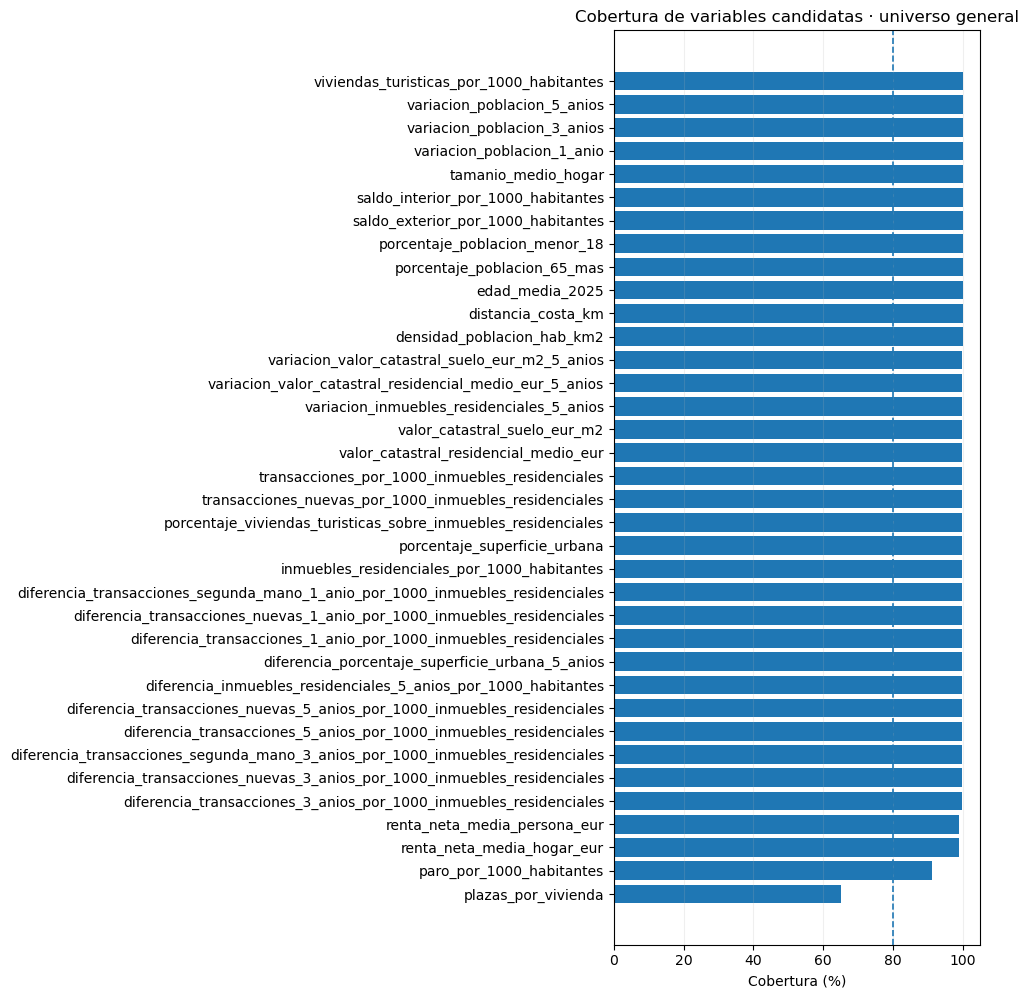

Variables que superan cobertura · general: 35


In [79]:
# % máximo de nulos que consideraremos para mantener una variable
MAX_MISSING_GENERAL = 20.0

def coverage_table(data, features):
    rows = []
    for c in features:
        rows.append({
            'variable': c,
            'n': len(data),
            'n_validos': int(data[c].notna().sum()),
            'n_nulos': int(data[c].isna().sum()),
            'nulos_pct': float(data[c].isna().mean() * 100),
            'cobertura_pct': float(data[c].notna().mean() * 100),
        })
    return pd.DataFrame(rows).sort_values(['nulos_pct', 'variable'], ascending=[False, True])


coverage_general = coverage_table(df_model, general_step1)
coverage_general['decision'] = np.where(
    coverage_general['nulos_pct'] <= MAX_MISSING_GENERAL,
    'mantener',
    'excluir_baja_cobertura'
)

display(coverage_general.round(2))

# Representamos el % de valores nulos de cada variable
fig, ax = plt.subplots(figsize=(10, max(5, len(coverage_general) * 0.28)))
plot_data = coverage_general.sort_values('cobertura_pct')
ax.barh(plot_data['variable'], plot_data['cobertura_pct'])
ax.axvline(100 - MAX_MISSING_GENERAL, linestyle='--', linewidth=1.2)
ax.set(xlabel='Cobertura (%)', title='Cobertura de variables candidatas · universo general')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
plt.show()

features_general_coverage = coverage_general.loc[
    coverage_general['decision'] == 'mantener', 'variable'
].tolist()

print(f'Variables que superan cobertura · general: {len(features_general_coverage)}')


### Universo específico con alquiler

Analicemos ahora qué variables mantendremos en el clustering específico. Consideraremos municipios con más de 5.000 habitantes.

,variable,n,n_validos,n_nulos,nulos_pct,cobertura_pct,decision
18,plazas_por_vivienda,1231,1192,39,3.17,96.83,mantener
44,variacion_alquiler_colectiva_aproximado_eur_m2...,1231,1193,38,3.09,96.91,mantener
42,variacion_alquiler_precio_colectiva_mediana_3_...,1231,1193,38,3.09,96.91,mantener
43,variacion_alquiler_colectiva_aproximado_eur_m2...,1231,1201,30,2.44,97.56,mantener
41,variacion_alquiler_precio_colectiva_mediana_1_...,1231,1201,30,2.44,97.56,mantener
39,alquiler_colectiva_aproximado_eur_m2,1231,1207,24,1.95,98.05,mantener
36,alquiler_precio_colectiva_rango_intercuartilico,1231,1207,24,1.95,98.05,mantener
37,alquiler_superficie_colectiva_mediana,1231,1207,24,1.95,98.05,mantener
38,alquiler_superficie_colectiva_rango_intercuart...,1231,1207,24,1.95,98.05,mantener
40,esfuerzo_alquiler_colectiva_pct,1231,1207,24,1.95,98.05,mantener


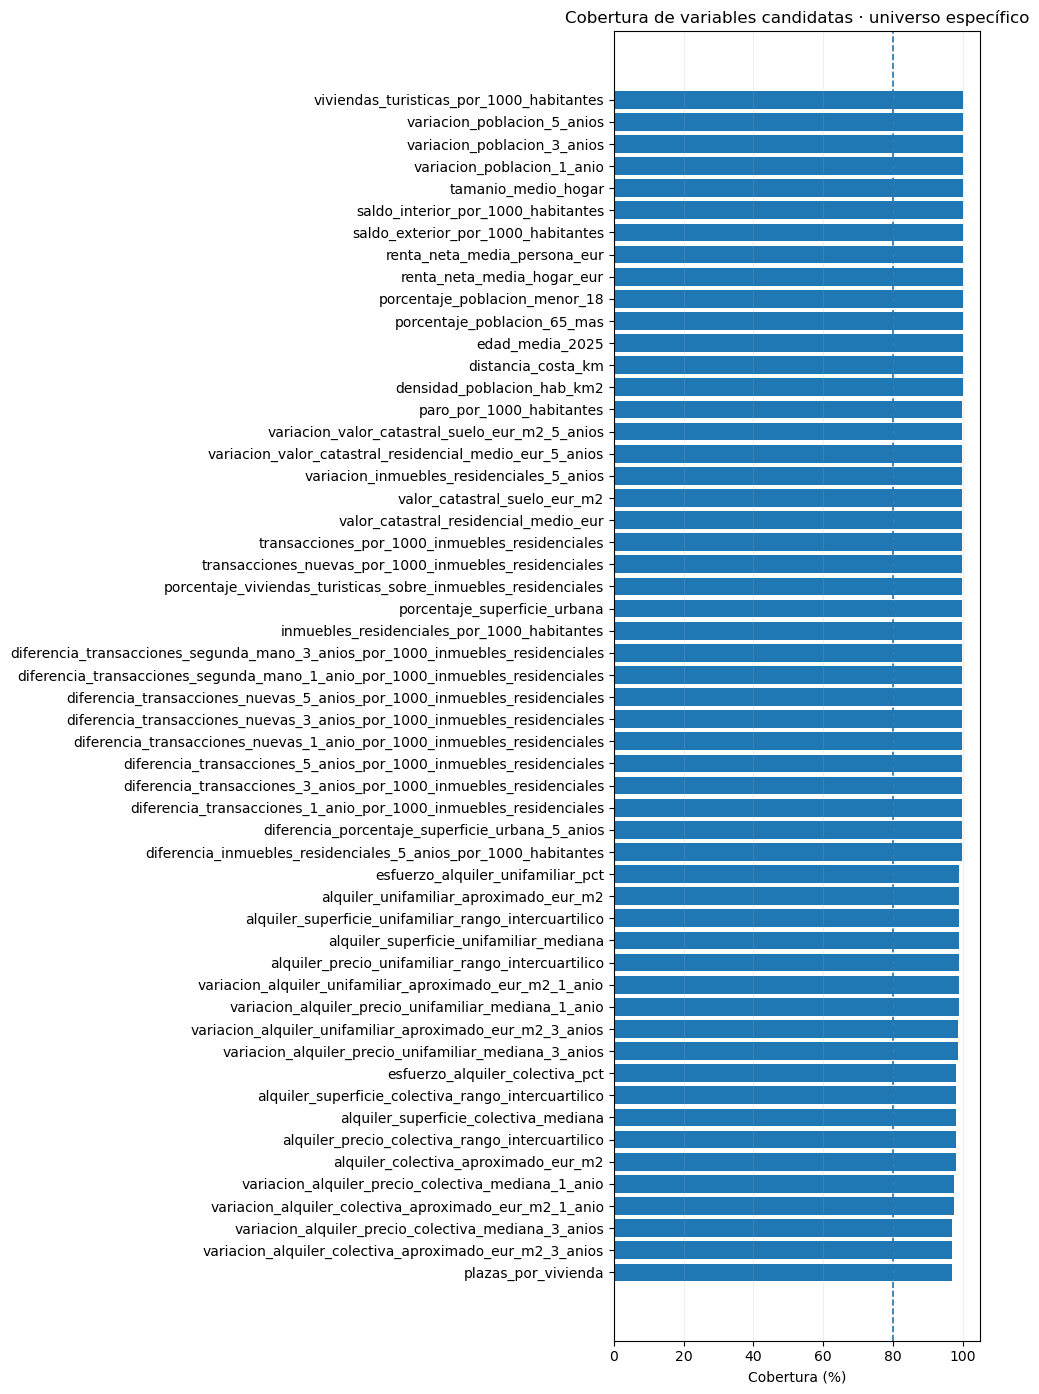

Municipios en universo específico: 1,231
Variables que superan cobertura · específico: 54


In [80]:
MIN_POP_SPECIFIC = 5_000         # sustituir por el umbral justificado en el EDA
MAX_MISSING_SPECIFIC = 20.0

df_specific = df_model.loc[
    pd.to_numeric(df_model['poblacion_2025'], errors='coerce') >= MIN_POP_SPECIFIC
].copy()

coverage_specific = coverage_table(df_specific, specific_step1)
coverage_specific['decision'] = np.where(
    coverage_specific['nulos_pct'] <= MAX_MISSING_SPECIFIC,
    'mantener',
    'excluir_baja_cobertura'
)

display(coverage_specific.round(2))

fig, ax = plt.subplots(figsize=(10, max(5, len(coverage_specific) * 0.26)))
plot_data = coverage_specific.sort_values('cobertura_pct')
ax.barh(plot_data['variable'], plot_data['cobertura_pct'])
ax.axvline(100 - MAX_MISSING_SPECIFIC, linestyle='--', linewidth=1.2)
ax.set(xlabel='Cobertura (%)', title='Cobertura de variables candidatas · universo específico')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
plt.show()

features_specific_coverage = coverage_specific.loc[
    coverage_specific['decision'] == 'mantener', 'variable'
].tolist()

print(f'Municipios en universo específico: {len(df_specific):,}')
print(f'Variables que superan cobertura · específico: {len(features_specific_coverage)}')


## Eliminar variables muy correlacionadas

Se calcula la correlación de **Spearman**, más robusta ante relaciones monótonas no lineales que Pearson.

Cuando `|ρ| >= 0.90, se conservaremos la variable con menor porcentaje de nulos.


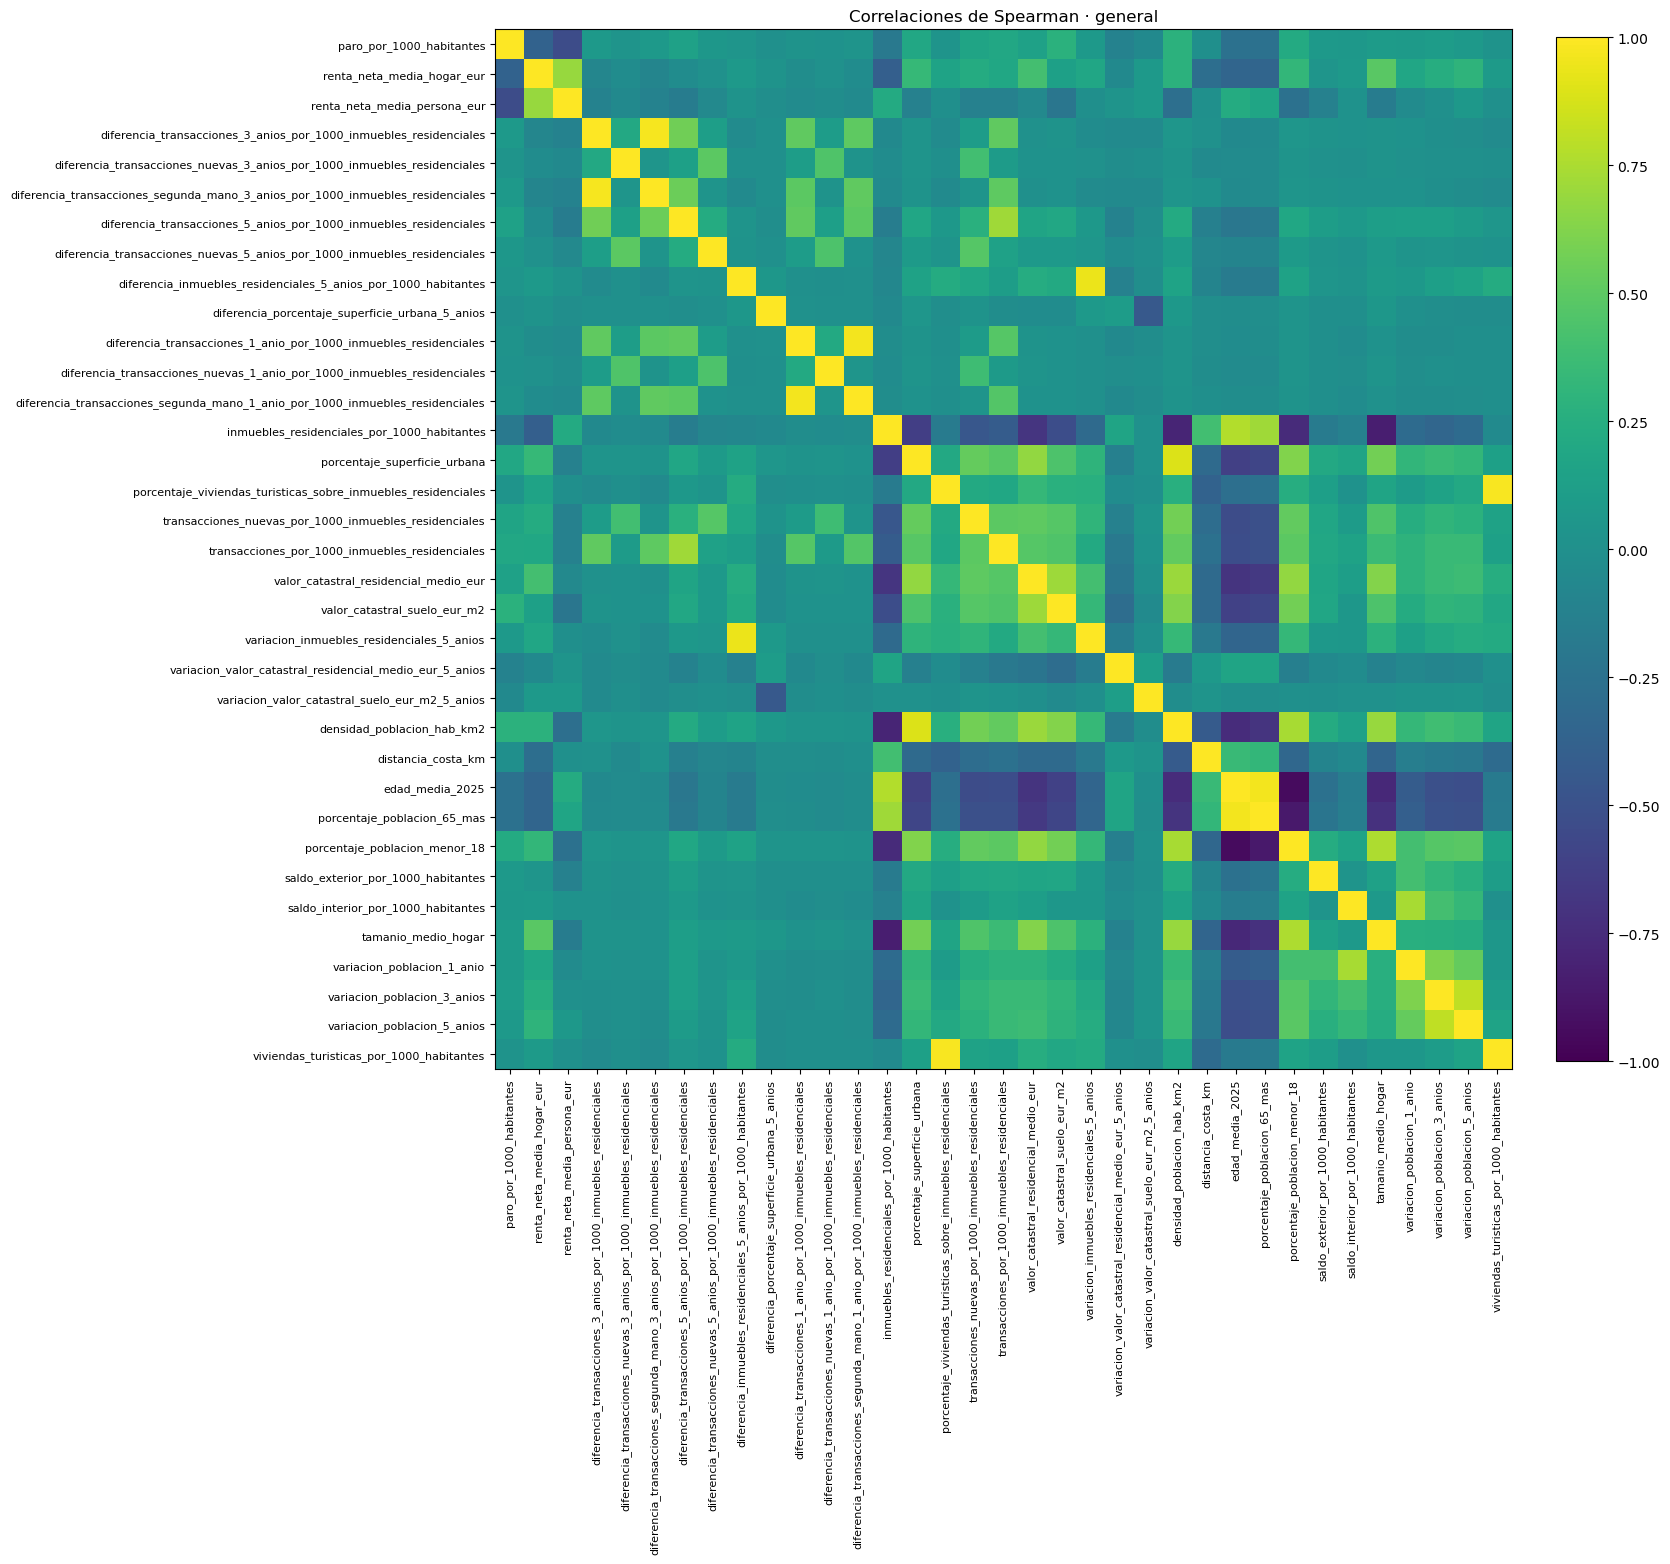

,eliminada,se_conserva,spearman_abs
0,porcentaje_poblacion_65_mas,edad_media_2025,0.964172
1,porcentaje_poblacion_menor_18,edad_media_2025,0.942388
2,diferencia_transacciones_segunda_mano_1_anio_p...,diferencia_transacciones_1_anio_por_1000_inmue...,0.964675
3,porcentaje_viviendas_turisticas_sobre_inmueble...,viviendas_turisticas_por_1000_habitantes,0.980210
4,variacion_inmuebles_residenciales_5_anios,diferencia_inmuebles_residenciales_5_anios_por...,0.940558
5,diferencia_transacciones_segunda_mano_3_anios_...,diferencia_transacciones_3_anios_por_1000_inmu...,0.969033


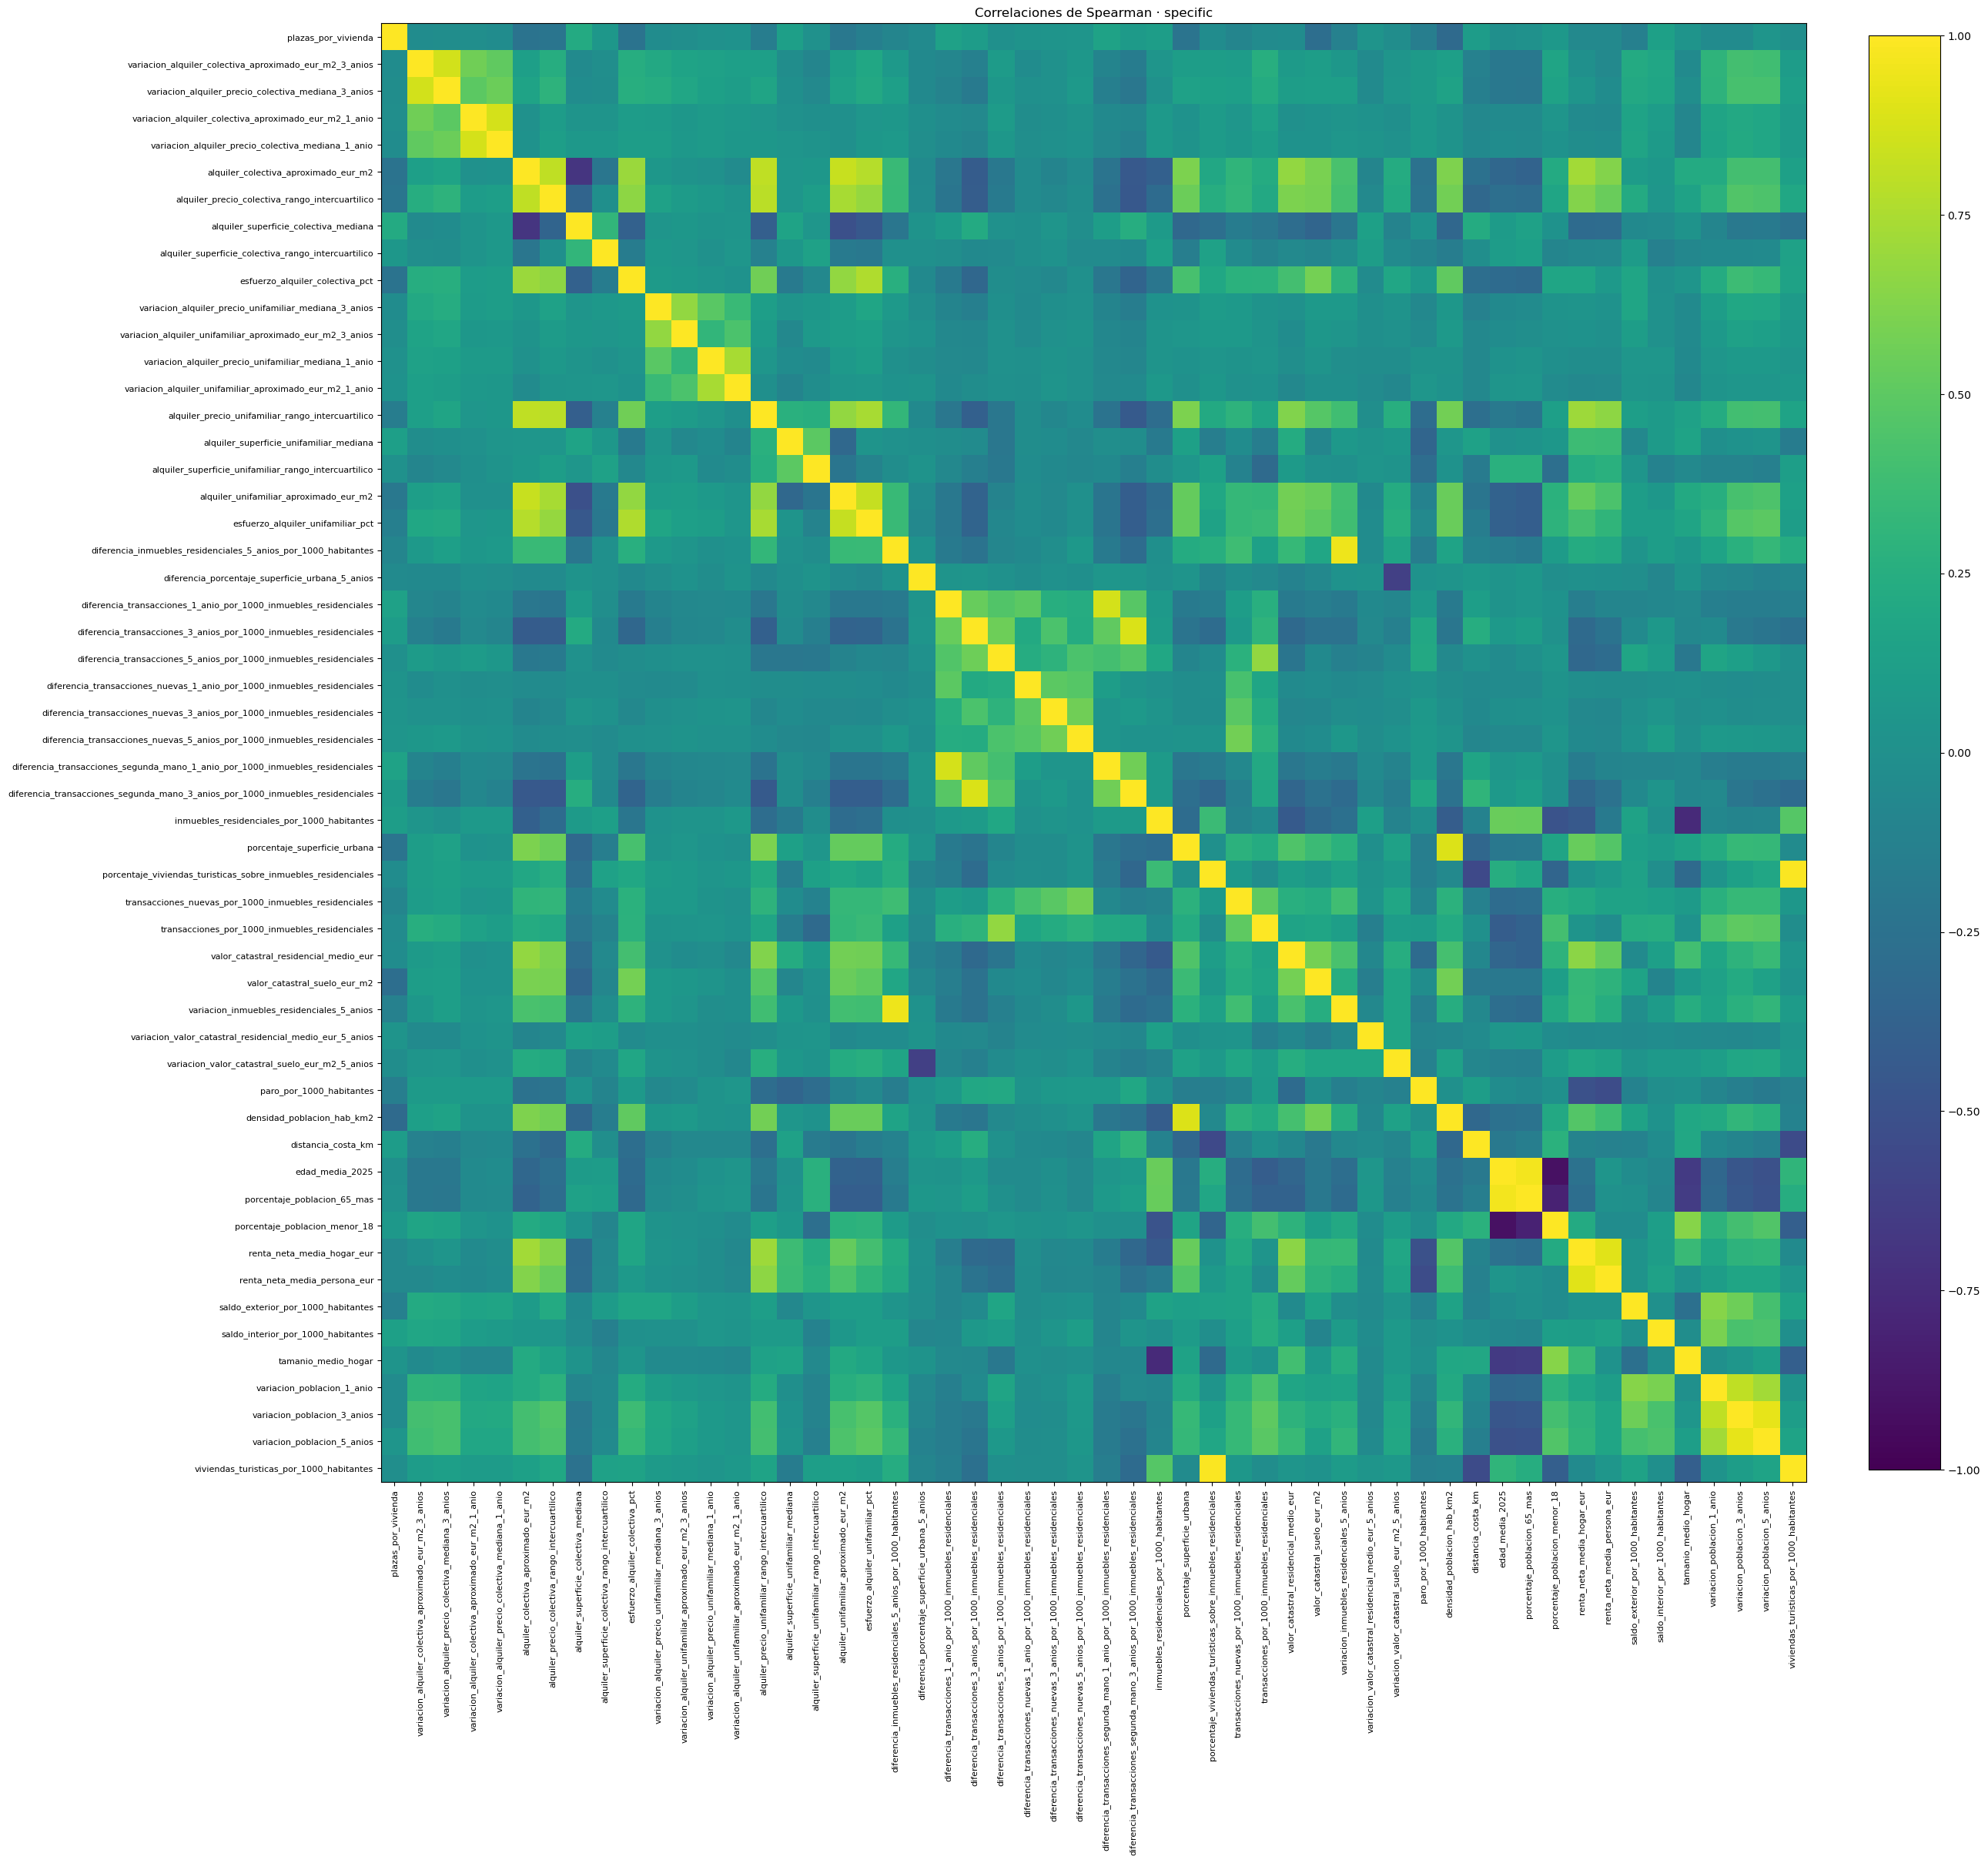

,eliminada,se_conserva,spearman_abs
0,porcentaje_poblacion_65_mas,edad_media_2025,0.963636
1,porcentaje_poblacion_menor_18,edad_media_2025,0.907771
2,renta_neta_media_persona_eur,renta_neta_media_hogar_eur,0.908076
3,variacion_poblacion_5_anios,variacion_poblacion_3_anios,0.925640
4,porcentaje_viviendas_turisticas_sobre_inmueble...,viviendas_turisticas_por_1000_habitantes,0.991335
5,variacion_inmuebles_residenciales_5_anios,diferencia_inmuebles_residenciales_5_anios_por...,0.948390



FEATURES FINALES · GENERAL
 - densidad_poblacion_hab_km2
 - distancia_costa_km
 - edad_media_2025
 - saldo_exterior_por_1000_habitantes
 - saldo_interior_por_1000_habitantes
 - tamanio_medio_hogar
 - variacion_poblacion_1_anio
 - variacion_poblacion_3_anios
 - variacion_poblacion_5_anios
 - viviendas_turisticas_por_1000_habitantes
 - diferencia_inmuebles_residenciales_5_anios_por_1000_habitantes
 - diferencia_porcentaje_superficie_urbana_5_anios
 - diferencia_transacciones_1_anio_por_1000_inmuebles_residenciales
 - diferencia_transacciones_nuevas_1_anio_por_1000_inmuebles_residenciales
 - inmuebles_residenciales_por_1000_habitantes
 - porcentaje_superficie_urbana
 - transacciones_nuevas_por_1000_inmuebles_residenciales
 - transacciones_por_1000_inmuebles_residenciales
 - valor_catastral_residencial_medio_eur
 - valor_catastral_suelo_eur_m2
 - variacion_valor_catastral_residencial_medio_eur_5_anios
 - variacion_valor_catastral_suelo_eur_m2_5_anios
 - diferencia_transacciones_5_anios_po

In [81]:
HIGH_CORR_THRESHOLD = 0.90  

def remove_high_correlation(data, features, threshold=0.90):
    if len(features) <= 1:
        return features.copy(), pd.DataFrame(), pd.DataFrame()

    numeric = data[features].apply(pd.to_numeric, errors='coerce')
    corr = numeric.corr(method='spearman')
    abs_corr = corr.abs()

    missing = numeric.isna().mean()
    priority = {f: i for i, f in enumerate(features)}
    ordered = sorted(features, key=lambda f: (missing[f], priority[f]))

    kept = []
    removed = []
    for feature in ordered:
        conflicts = [k for k in kept if abs_corr.loc[feature, k] >= threshold]
        if conflicts:
            against = max(conflicts, key=lambda k: abs_corr.loc[feature, k])
            removed.append({
                'eliminada': feature,
                'se_conserva': against,
                'spearman_abs': float(abs_corr.loc[feature, against]),
            })
        else:
            kept.append(feature)

    return kept, pd.DataFrame(removed), corr


def correlation_heatmap(corr, universe, filename):
    if corr.empty:
        return
    n = len(corr)
    fig, ax = plt.subplots(figsize=(max(8, n * 0.48), max(7, n * 0.45)))
    im = ax.imshow(corr.values, vmin=-1, vmax=1, aspect='auto')
    ax.set_xticks(range(n), corr.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(n), corr.index, fontsize=8)
    ax.set_title(f'Correlaciones de Spearman · {universe}')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    plt.show()


features_general, high_corr_general, corr_general = remove_high_correlation(
    df_model,
    features_general_coverage,
    HIGH_CORR_THRESHOLD
)
correlation_heatmap(corr_general, 'general', '14_spearman_before_filter.png')

display(high_corr_general)

features_specific, high_corr_specific, corr_specific = remove_high_correlation(
    df_specific,
    features_specific_coverage,
    HIGH_CORR_THRESHOLD
)
correlation_heatmap(corr_specific, 'specific', '14_spearman_before_filter.png')

display(high_corr_specific)

print('\nFEATURES FINALES · GENERAL')
for c in features_general:
    print(' -', c)

print('\nFEATURES FINALES · ESPECÍFICO')
for c in features_specific:
    print(' -', c)


## Resumen de selección

Se guardan las listas finales para que el siguiente notebook pueda reproducir exactamente qué variables se utilizaron.


In [82]:
selection_summary = pd.DataFrame({
    'universo': ['general', 'specific'],
    'municipios': [len(df_model), len(df_specific)],
    'candidatas_tras_redundancia': [len(general_step1), len(specific_step1)],
    'tras_cobertura': [len(features_general_coverage), len(features_specific_coverage)],
    'variables_finales': [len(features_general), len(features_specific)],
})

display(selection_summary)

# Bucket donde se guardarán los CSV
BUCKET = "s3-tfm-athena-results-159012148774-eu-west-3"
# Cliente S3
s3_client = boto3.client("s3")

def save_dataframe_s3(data: pd.DataFrame, universe: str, filename: str, index: bool = True) -> str:
    key = f"reports/{universe}/{filename}"
    payload = data.to_csv(index=index).encode("utf-8")
    s3_client.put_object(Bucket=BUCKET, Key=key, Body=payload, ContentType="text/csv")
    uri = f"s3://{BUCKET}/{key}"
    print(f"Tabla guardada → {uri}")
    return uri

save_dataframe_s3(
    pd.DataFrame({'variable': features_general}),
    'general', 'selected_features.csv', index=False
)
save_dataframe_s3(
    pd.DataFrame({'variable': features_specific}),
    'specific', 'selected_features.csv', index=False
)

,universo,municipios,candidatas_tras_redundancia,tras_cobertura,variables_finales
0,general,7608,36,35,29
1,specific,1231,54,54,48


Tabla guardada → s3://s3-tfm-athena-results-159012148774-eu-west-3/reports/general/selected_features.csv
Tabla guardada → s3://s3-tfm-athena-results-159012148774-eu-west-3/reports/specific/selected_features.csv


's3://s3-tfm-athena-results-159012148774-eu-west-3/reports/specific/selected_features.csv'

# Preprocesar los datos


## Imputación de valores nulos

Realizamos la imputación de valores nulos después de eliminar variables con baja cobertura y alta correlación.

Para los valores faltantes se utilizará IterativeImputer, que estima cada dato ausente a partir de las relaciones existentes con el resto de variables disponibles.

Además, se incorpora 'poblacion_2025' como variable auxiliar durante la imputación, ya que el tamaño del municipio puede aportar información relevante para estimar determinados valores. Esta variable se elimina posteriormente y no se tendrá en cuenta para el clustering.

In [83]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Utilizaremos la población para imputar, pero no la usaremos para el clustering
AUXILIARY_IMPUTATION_VARS = [
    'poblacion_2025'
]


def prepare_numeric_matrix(data, features):
    return (
        data[features]
        .apply(pd.to_numeric, errors='coerce')
        .replace([np.inf, -np.inf], np.nan)
    )


def impute_iterative(X):
    imputer = IterativeImputer(
        initial_strategy='median',
        max_iter=20,
        tol=1e-3,
        random_state=42,
        skip_complete=True
    )

    values = imputer.fit_transform(X)

    X_imp = pd.DataFrame(
        values,
        columns=X.columns,
        index=X.index
    )

    report = pd.DataFrame({
        'variable': X.columns,
        'nulos_antes': X.isna().sum().values,
        'imputados_pct': X.isna().mean().values * 100,
        'nulos_despues': X_imp.isna().sum().values,
    })

    return X_imp, imputer, report


# ============================================================
# CLUSTERING GENERAL
# ============================================================

general_imputation_features = list(dict.fromkeys(
    features_general + AUXILIARY_IMPUTATION_VARS
))

Xg_raw_full = prepare_numeric_matrix(
    df_model,
    general_imputation_features
)

Xg_imp_full, imputer_general, imputation_general = impute_iterative(
    Xg_raw_full
)

# Nos quedamos únicamente con las features del clustering.
# poblacion_ign ha servido para imputar, pero NO entra al modelo.
Xg_imp = Xg_imp_full[features_general].copy()


# ============================================================
# CLUSTERING ESPECÍFICO
# ============================================================

specific_imputation_features = list(dict.fromkeys(
    features_specific + AUXILIARY_IMPUTATION_VARS
))

Xs_raw_full = prepare_numeric_matrix(
    df_specific,
    specific_imputation_features
)

Xs_imp_full, imputer_specific, imputation_specific = impute_iterative(
    Xs_raw_full
)

# Eliminamos las variables auxiliares tras la imputación
Xs_imp = Xs_imp_full[features_specific].copy()


# ============================================================
# INFORMES
# ============================================================

print('Imputación iterativa · general')
display(
    imputation_general[
        imputation_general['variable'].isin(features_general)
    ]
    .sort_values('imputados_pct', ascending=False)
    .round(3)
)

print('Imputación iterativa · específico')
display(
    imputation_specific[
        imputation_specific['variable'].isin(features_specific)
    ]
    .sort_values('imputados_pct', ascending=False)
    .round(3)
)


# Comprobaciones
print('\nDimensiones tras imputación:')
print(f'General:    {Xg_imp.shape}')
print(f'Específico: {Xs_imp.shape}')

assert list(Xg_imp.columns) == list(features_general)
assert list(Xs_imp.columns) == list(features_specific)

assert Xg_imp.isna().sum().sum() == 0
assert Xs_imp.isna().sum().sum() == 0

Imputación iterativa · general


,variable,nulos_antes,imputados_pct,nulos_despues
28,paro_por_1000_habitantes,672,8.833,0
26,renta_neta_media_hogar_eur,73,0.960,0
27,renta_neta_media_persona_eur,73,0.960,0
24,diferencia_transacciones_3_anios_por_1000_inmu...,5,0.066,0
25,diferencia_transacciones_nuevas_3_anios_por_10...,5,0.066,0
22,diferencia_transacciones_5_anios_por_1000_inmu...,4,0.053,0
23,diferencia_transacciones_nuevas_5_anios_por_10...,4,0.053,0
13,diferencia_transacciones_nuevas_1_anio_por_100...,2,0.026,0
11,diferencia_porcentaje_superficie_urbana_5_anios,2,0.026,0
12,diferencia_transacciones_1_anio_por_1000_inmue...,2,0.026,0


Imputación iterativa · específico


,variable,nulos_antes,imputados_pct,nulos_despues
47,plazas_por_vivienda,39,3.168,0
45,variacion_alquiler_colectiva_aproximado_eur_m2...,38,3.087,0
46,variacion_alquiler_precio_colectiva_mediana_3_...,38,3.087,0
43,variacion_alquiler_colectiva_aproximado_eur_m2...,30,2.437,0
44,variacion_alquiler_precio_colectiva_mediana_1_...,30,2.437,0
42,esfuerzo_alquiler_colectiva_pct,24,1.950,0
39,alquiler_precio_colectiva_rango_intercuartilico,24,1.950,0
38,alquiler_colectiva_aproximado_eur_m2,24,1.950,0
40,alquiler_superficie_colectiva_mediana,24,1.950,0
41,alquiler_superficie_colectiva_rango_intercuart...,24,1.950,0



Dimensiones tras imputación:
General:    (7608, 29)
Específico: (1231, 48)


## Tratamiento de outliers

Para el tratamiento de outliers no usaremos z-score debido a la asimetría que presentan numerosas variables.

No se eliminarán municipios extremos, porque pueden representar mercados reales de interés (grandes ciudades, destinos turísticos, municipios costeros, etc.).

Se utiliza una **winsorización** en los cuantiles 0,5 % y 99,5 % para reducir la capacidad de unos pocos valores extremos de dominar las distancias.

Una winsorización en los cuantiles 0,5% y 99,5% consiste en aplicar lo siguiente:

    - Todo valor por debajo del percentil 0,5 se sustituye por el valor del percentil 0,5;
    - Todo valor por encima del percentil 99,5 se sustituye por el valor del percentil 99,5;
    - El 99% central de los datos queda exactamente igual.

In [84]:
OUTLIER_LOWER_Q = 0.005          # winsorización 0.5 %
OUTLIER_UPPER_Q = 0.995          # winsorización 99.5 %

def winsorize_dataframe(X, lower_q=0.005, upper_q=0.995):
    X_out = X.copy()
    rows = []
    bounds = {}

    for c in X.columns:
        lower = float(X[c].quantile(lower_q))
        upper = float(X[c].quantile(upper_q))
        before = X[c].copy()
        X_out[c] = X[c].clip(lower=lower, upper=upper)
        changed = int((before != X_out[c]).sum())

        bounds[c] = (lower, upper)
        rows.append({
            'variable': c,
            'limite_inferior': lower,
            'limite_superior': upper,
            'n_modificados': changed,
            'modificados_pct': float(changed / len(X) * 100),
        })

    return X_out, bounds, pd.DataFrame(rows)


Xg_wins, winsor_bounds_general, outliers_general = winsorize_dataframe(
    Xg_imp, OUTLIER_LOWER_Q, OUTLIER_UPPER_Q
)
Xs_wins, winsor_bounds_specific, outliers_specific = winsorize_dataframe(
    Xs_imp, OUTLIER_LOWER_Q, OUTLIER_UPPER_Q
)

print('Outliers modificados · general')
display(outliers_general.sort_values('modificados_pct', ascending=False).round(3))
print('Outliers modificados · específico')
display(outliers_specific.sort_values('modificados_pct', ascending=False).round(3))


Outliers modificados · general


,variable,limite_inferior,limite_superior,n_modificados,modificados_pct
0,densidad_poblacion_hab_km2,0.590,5134.028,78,1.025
2,edad_media_2025,37.992,67.677,78,1.025
3,saldo_exterior_por_1000_habitantes,-40.946,92.773,78,1.025
4,saldo_interior_por_1000_habitantes,-140.471,146.332,78,1.025
8,variacion_poblacion_5_anios,-28.188,45.756,78,1.025
11,diferencia_porcentaje_superficie_urbana_5_anios,-1.259,3.139,78,1.025
10,diferencia_inmuebles_residenciales_5_anios_por...,-271.920,142.743,78,1.025
23,diferencia_transacciones_nuevas_5_anios_por_10...,-12.813,16.121,78,1.025
24,diferencia_transacciones_3_anios_por_1000_inmu...,-43.140,54.620,78,1.025
18,valor_catastral_residencial_medio_eur,8856.877,141544.910,78,1.025


Outliers modificados · específico


,variable,limite_inferior,limite_superior,n_modificados,modificados_pct
0,densidad_poblacion_hab_km2,11.978,13966.743,14,1.137
2,edad_media_2025,36.678,52.559,14,1.137
3,renta_neta_media_hogar_eur,23881.100,74121.100,14,1.137
4,saldo_exterior_por_1000_habitantes,-2.958,41.807,14,1.137
6,tamanio_medio_hogar,2.133,3.068,14,1.137
5,saldo_interior_por_1000_habitantes,-14.974,30.864,14,1.137
7,variacion_poblacion_1_anio,-1.496,5.252,14,1.137
8,variacion_poblacion_3_anios,-3.381,17.663,14,1.137
14,diferencia_transacciones_3_anios_por_1000_inmu...,-31.616,30.685,14,1.137
10,paro_por_1000_habitantes,11.810,103.862,14,1.137


## Transformaciones logarítmicas

Se aplica `log1p` únicamente cuando:
- la variable es no negativa;
- su asimetría es positiva y superior al umbral definido.

Las variables de variación o diferencia que pueden tomar valores negativos no se transforman logarítmicamente.


In [85]:
SKEW_LOG_THRESHOLD = 1.0         # log1p si skew > 1 y valor mínimo >= 0

def apply_log_when_needed(X, skew_threshold=1.0):
    X_trans = X.copy()
    rows = []
    log_features = []

    for c in X.columns:
        skew_before = float(X[c].skew())
        minimum = float(X[c].min())
        action = 'none'

        if skew_before > skew_threshold and minimum >= 0:
            X_trans[c] = np.log1p(X[c])
            action = 'log1p'
            log_features.append(c)

        rows.append({
            'variable': c,
            'asimetria_antes': skew_before,
            'minimo': minimum,
            'transformacion': action,
            'asimetria_despues': float(X_trans[c].skew()),
        })

    return X_trans, log_features, pd.DataFrame(rows)


Xg_trans, log_features_general, transform_general = apply_log_when_needed(
    Xg_wins, SKEW_LOG_THRESHOLD
)
Xs_trans, log_features_specific, transform_specific = apply_log_when_needed(
    Xs_wins, SKEW_LOG_THRESHOLD
)

print('Log1p · general:', log_features_general)
print('Log1p · específico:', log_features_specific)

display(transform_general.sort_values('asimetria_antes', ascending=False).round(3))
display(transform_specific.sort_values('asimetria_antes', ascending=False).round(3))

Log1p · general: ['densidad_poblacion_hab_km2', 'viviendas_turisticas_por_1000_habitantes', 'inmuebles_residenciales_por_1000_habitantes', 'porcentaje_superficie_urbana', 'transacciones_nuevas_por_1000_inmuebles_residenciales', 'transacciones_por_1000_inmuebles_residenciales', 'valor_catastral_residencial_medio_eur', 'valor_catastral_suelo_eur_m2', 'renta_neta_media_hogar_eur']
Log1p · específico: ['densidad_poblacion_hab_km2', 'distancia_costa_km', 'renta_neta_media_hogar_eur', 'viviendas_turisticas_por_1000_habitantes', 'inmuebles_residenciales_por_1000_habitantes', 'porcentaje_superficie_urbana', 'transacciones_nuevas_por_1000_inmuebles_residenciales', 'transacciones_por_1000_inmuebles_residenciales', 'valor_catastral_residencial_medio_eur', 'valor_catastral_suelo_eur_m2', 'alquiler_precio_unifamiliar_rango_intercuartilico', 'alquiler_unifamiliar_aproximado_eur_m2', 'esfuerzo_alquiler_unifamiliar_pct', 'alquiler_precio_colectiva_rango_intercuartilico', 'plazas_por_vivienda']


,variable,asimetria_antes,minimo,transformacion,asimetria_despues
0,densidad_poblacion_hab_km2,6.730,0.590,log1p,0.954
11,diferencia_porcentaje_superficie_urbana_5_anios,5.894,-1.259,none,5.894
16,transacciones_nuevas_por_1000_inmuebles_reside...,4.499,0.000,log1p,2.230
20,variacion_valor_catastral_residencial_medio_eu...,3.815,-16.038,none,3.815
15,porcentaje_superficie_urbana,3.760,0.040,log1p,1.459
19,valor_catastral_suelo_eur_m2,3.684,2.150,log1p,0.474
9,viviendas_turisticas_por_1000_habitantes,3.538,0.000,log1p,0.692
21,variacion_valor_catastral_suelo_eur_m2_5_anios,2.514,-59.015,none,2.514
14,inmuebles_residenciales_por_1000_habitantes,2.400,329.466,log1p,0.572
18,valor_catastral_residencial_medio_eur,1.700,8856.877,log1p,0.091


,variable,asimetria_antes,minimo,transformacion,asimetria_despues
27,variacion_valor_catastral_residencial_medio_eu...,7.265,-24.108,none,7.265
28,variacion_valor_catastral_suelo_eur_m2_5_anios,6.506,-60.147,none,6.506
12,diferencia_porcentaje_superficie_urbana_5_anios,5.488,-2.508,none,5.488
0,densidad_poblacion_hab_km2,4.785,11.978,log1p,0.277
9,viviendas_turisticas_por_1000_habitantes,3.760,0.000,log1p,1.048
23,transacciones_nuevas_por_1000_inmuebles_reside...,3.092,0.000,log1p,0.799
26,valor_catastral_suelo_eur_m2,2.555,5.780,log1p,0.002
29,alquiler_precio_unifamiliar_rango_intercuartilico,2.419,85.010,log1p,0.331
21,inmuebles_residenciales_por_1000_habitantes,2.077,302.414,log1p,1.059
39,alquiler_precio_colectiva_rango_intercuartilico,1.810,60.315,log1p,0.277


## Escalado

Tras imputación, winsorización y transformaciones, aplicaremos `StandardScaler` a todas las variables (media 0 y desviación estándar 1) para que la escala original no determine las distancias en el clustering.


In [86]:
def standardize(X):
    scaler = StandardScaler()
    values = scaler.fit_transform(X)
    X_scaled = pd.DataFrame(values, columns=X.columns, index=X.index)
    return X_scaled, scaler


X_general_scaled, scaler_general = standardize(Xg_trans)
X_specific_scaled, scaler_specific = standardize(Xs_trans)

check_general = pd.DataFrame({
    'media': X_general_scaled.mean(),
    'std': X_general_scaled.std(ddof=0),
})
check_specific = pd.DataFrame({
    'media': X_specific_scaled.mean(),
    'std': X_specific_scaled.std(ddof=0),
})

print('Comprobación StandardScaler · general')
display(check_general.round(4))
print('Comprobación StandardScaler · específico')
display(check_specific.round(4))

Comprobación StandardScaler · general


,media,std
densidad_poblacion_hab_km2,0.0,1.0
distancia_costa_km,0.0,1.0
edad_media_2025,-0.0,1.0
saldo_exterior_por_1000_habitantes,-0.0,1.0
saldo_interior_por_1000_habitantes,0.0,1.0
tamanio_medio_hogar,0.0,1.0
variacion_poblacion_1_anio,0.0,1.0
variacion_poblacion_3_anios,-0.0,1.0
variacion_poblacion_5_anios,-0.0,1.0
viviendas_turisticas_por_1000_habitantes,-0.0,1.0


Comprobación StandardScaler · específico


,media,std
densidad_poblacion_hab_km2,-0.0,1.0
distancia_costa_km,-0.0,1.0
edad_media_2025,0.0,1.0
renta_neta_media_hogar_eur,0.0,1.0
saldo_exterior_por_1000_habitantes,-0.0,1.0
saldo_interior_por_1000_habitantes,-0.0,1.0
tamanio_medio_hogar,0.0,1.0
variacion_poblacion_1_anio,-0.0,1.0
variacion_poblacion_3_anios,0.0,1.0
viviendas_turisticas_por_1000_habitantes,-0.0,1.0


## Guardamos el preprocesador reproducible


In [102]:
PROVINCIAS_EXCLUIDAS = [
    'Araba/Álava',
    'Bizkaia',
    'Gipuzkoa',
    'Navarra'
]

preprocessor_general = {
    'features': features_general,

    'imputation_features': general_imputation_features,
    'auxiliary_imputation_vars': AUXILIARY_IMPUTATION_VARS,

    'imputer': imputer_general,
    'winsor_bounds': winsor_bounds_general,
    'log_features': log_features_general,
    'scaler': scaler_general,

    # Universo utilizado para entrenar el preprocesado
    'excluded_provinces': PROVINCIAS_EXCLUIDAS,
}


preprocessor_specific = {
    'features': features_specific,

    'imputation_features': specific_imputation_features,
    'auxiliary_imputation_vars': AUXILIARY_IMPUTATION_VARS,

    'imputer': imputer_specific,
    'winsor_bounds': winsor_bounds_specific,
    'log_features': log_features_specific,
    'scaler': scaler_specific,

    # Universo utilizado
    'excluded_provinces': PROVINCIAS_EXCLUIDAS,
    'min_population': MIN_POP_SPECIFIC,
}

# Bucket donde se guardarán los CSV
BUCKET = "s3-tfm-athena-results-159012148774-eu-west-3"
# Cliente S3
s3_client = boto3.client("s3")

def save_pickle_s3(obj, universe: str, filename: str) -> str:
    key = f"clustering/{universe}/artifacts/{filename}"

    s3_client.put_object(
        Bucket=BUCKET,
        Key=key,
        Body=pickle.dumps(obj, protocol=pickle.HIGHEST_PROTOCOL),
        ContentType="application/octet-stream"
    )

    uri = f"s3://{BUCKET}/{key}"
    print(f"Artefacto guardado → {uri}")

    return uri

save_pickle_s3(
    preprocessor_general,
    'general',
    'preprocessor.pkl'
)

save_pickle_s3(
    preprocessor_specific,
    'specific',
    'preprocessor.pkl'
)

Artefacto guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/general/artifacts/preprocessor.pkl
Artefacto guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/specific/artifacts/preprocessor.pkl


's3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/specific/artifacts/preprocessor.pkl'

# Reducción de dimensionalidad


## PCA y varianza explicada

PCA se utiliza como **herramienta diagnóstica y representación alternativa**, no como sustitución automática de las variables estandarizadas.

El notebook de clustering podrá comparar:
- `X_general_scaled` frente a `X_general_pca`;
- `X_specific_scaled` frente a `X_specific_pca`.


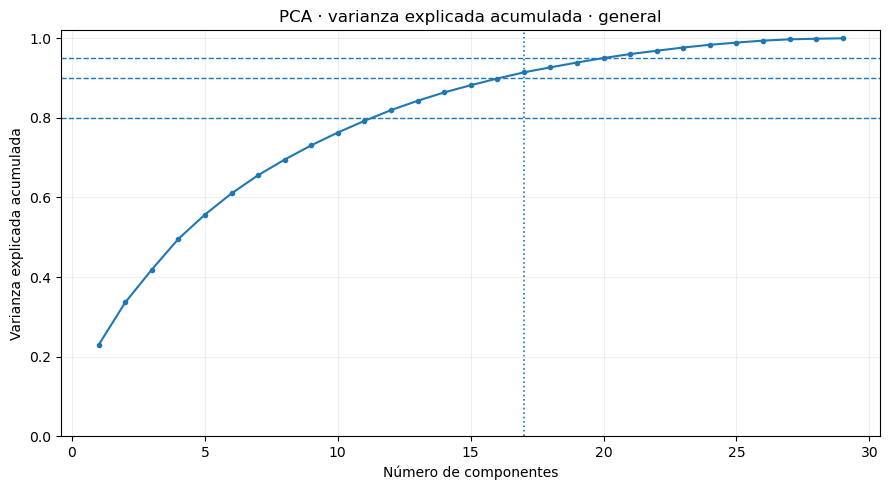

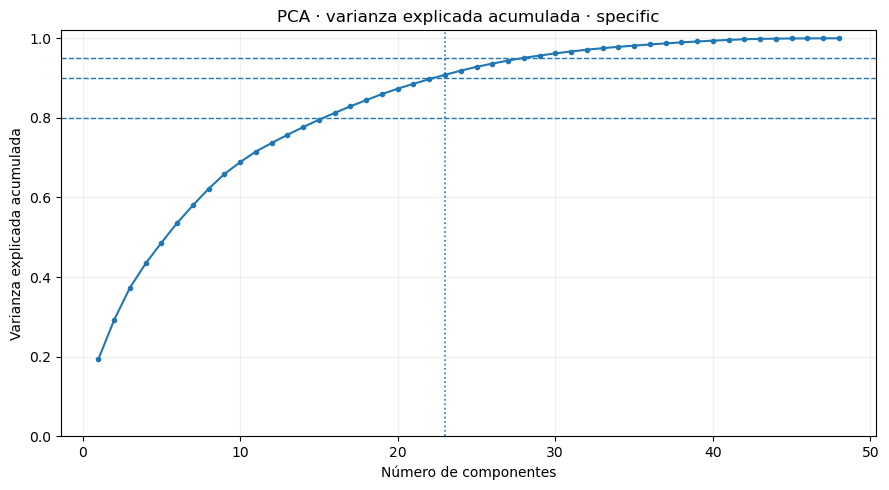

GENERAL


,objetivo_varianza,n_componentes
0,0.80,12
1,0.90,17
2,0.95,20


ESPECÍFICO


,objetivo_varianza,n_componentes
0,0.80,16
1,0.90,23
2,0.95,28


In [92]:
PCA_VARIANCE_TARGET = 0.90

def pca_diagnostics(X_scaled, universe, variance_target=0.90):
    pca_full = PCA()
    pca_full.fit(X_scaled)

    explained = pca_full.explained_variance_ratio_
    cumulative = np.cumsum(explained)

    def n_for(target):
        return int(np.argmax(cumulative >= target) + 1)

    n80 = n_for(0.80)
    n90 = n_for(0.90)
    n95 = n_for(0.95)
    n_target = n_for(variance_target)

    variance_table = pd.DataFrame({
        'componente': np.arange(1, len(explained) + 1),
        'varianza_explicada': explained,
        'varianza_acumulada': cumulative,
    })

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(
        variance_table['componente'],
        variance_table['varianza_acumulada'],
        marker='o', markersize=3
    )
    ax.axhline(0.80, linestyle='--', linewidth=1)
    ax.axhline(0.90, linestyle='--', linewidth=1)
    ax.axhline(0.95, linestyle='--', linewidth=1)
    ax.axvline(n_target, linestyle=':', linewidth=1.2)
    ax.set(
        xlabel='Número de componentes',
        ylabel='Varianza explicada acumulada',
        title=f'PCA · varianza explicada acumulada · {universe}'
    )
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

    summary = pd.DataFrame({
        'objetivo_varianza': [0.80, 0.90, 0.95],
        'n_componentes': [n80, n90, n95],
    })

    return pca_full, variance_table, summary, n_target


pca_full_general, pca_variance_general, pca_summary_general, n_pca_general = pca_diagnostics(
    X_general_scaled, 'general', PCA_VARIANCE_TARGET
)
pca_full_specific, pca_variance_specific, pca_summary_specific, n_pca_specific = pca_diagnostics(
    X_specific_scaled, 'specific', PCA_VARIANCE_TARGET
)

print('GENERAL')
display(pca_summary_general)
print('ESPECÍFICO')
display(pca_summary_specific)


## Interpretar las cargas de las componentes


In [95]:
def pca_loadings_table(pca, features, n_components=5, top_n=8):
    n_components = min(n_components, pca.components_.shape[0])
    loadings = pd.DataFrame(
        pca.components_[:n_components].T,
        index=features,
        columns=[f'PC{i}' for i in range(1, n_components + 1)]
    )

    rows = []
    for pc in loadings.columns:
        top = loadings[pc].abs().nlargest(min(top_n, len(loadings))).index
        for variable in top:
            rows.append({
                'componente': pc,
                'variable': variable,
                'carga': float(loadings.loc[variable, pc]),
                'carga_abs': float(abs(loadings.loc[variable, pc])),
            })
    return loadings, pd.DataFrame(rows)


loadings_general, top_loadings_general = pca_loadings_table(
    pca_full_general, features_general
)
loadings_specific, top_loadings_specific = pca_loadings_table(
    pca_full_specific, features_specific
)

print('Variables dominantes · PCA general')
display(top_loadings_general)
print('Variables dominantes · PCA específico')
display(top_loadings_specific)


Variables dominantes · PCA general


,componente,variable,carga,carga_abs
0,PC1,densidad_poblacion_hab_km2,0.337473,0.337473
1,PC1,edad_media_2025,-0.330617,0.330617
2,PC1,valor_catastral_residencial_medio_eur,0.307614,0.307614
3,PC1,inmuebles_residenciales_por_1000_habitantes,-0.306053,0.306053
4,PC1,porcentaje_superficie_urbana,0.301927,0.301927
5,PC1,tamanio_medio_hogar,0.286391,0.286391
6,PC1,valor_catastral_suelo_eur_m2,0.273196,0.273196
7,PC1,transacciones_nuevas_por_1000_inmuebles_reside...,0.242513,0.242513
8,PC2,diferencia_transacciones_3_anios_por_1000_inmu...,0.368826,0.368826
9,PC2,diferencia_transacciones_nuevas_3_anios_por_10...,0.365654,0.365654


Variables dominantes · PCA específico


,componente,variable,carga,carga_abs
0,PC1,alquiler_colectiva_aproximado_eur_m2,0.286561,0.286561
1,PC1,alquiler_precio_colectiva_rango_intercuartilico,0.279755,0.279755
2,PC1,alquiler_unifamiliar_aproximado_eur_m2,0.275543,0.275543
3,PC1,esfuerzo_alquiler_unifamiliar_pct,0.271248,0.271248
4,PC1,alquiler_precio_unifamiliar_rango_intercuartilico,0.271016,0.271016
5,PC1,esfuerzo_alquiler_colectiva_pct,0.236317,0.236317
6,PC1,valor_catastral_residencial_medio_eur,0.235183,0.235183
7,PC1,densidad_poblacion_hab_km2,0.228156,0.228156
8,PC2,diferencia_transacciones_5_anios_por_1000_inmu...,0.364712,0.364712
9,PC2,transacciones_por_1000_inmuebles_residenciales,0.336488,0.336488


## Construir las matrices PCA con el objetivo de varianza definido


In [96]:
RANDOM_STATE= 42

def build_pca_matrix(X_scaled, n_components):
    pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
    values = pca.fit_transform(X_scaled)
    X_pca = pd.DataFrame(
        values,
        index=X_scaled.index,
        columns=[f'PC{i}' for i in range(1, n_components + 1)]
    )
    return X_pca, pca


X_general_pca, pca_general = build_pca_matrix(X_general_scaled, n_pca_general)
X_specific_pca, pca_specific = build_pca_matrix(X_specific_scaled, n_pca_specific)

print(f'General: {X_general_scaled.shape[1]} variables → {X_general_pca.shape[1]} componentes')
print(f'Específico: {X_specific_scaled.shape[1]} variables → {X_specific_pca.shape[1]} componentes')


General: 29 variables → 17 componentes
Específico: 48 variables → 23 componentes


# 17. Salida para el notebook de clustering


In [101]:
metadata_cols = [c for c in [
    'codigo_ine', 'municipio', 'provincia', 'capital',
    'poblacion_2025', 'longitud', 'latitud'
] if c in df_model.columns]

meta_general = df_model.loc[X_general_scaled.index, metadata_cols].copy()
meta_specific = df_specific.loc[X_specific_scaled.index, metadata_cols].copy()

final_summary = pd.DataFrame([
    {
        'universo': 'general',
        'municipios': len(X_general_scaled),
        'features_seleccionadas': X_general_scaled.shape[1],
        'componentes_pca_objetivo': X_general_pca.shape[1],
        'varianza_pca': float(pca_general.explained_variance_ratio_.sum()),
    },
    {
        'universo': 'specific',
        'municipios': len(X_specific_scaled),
        'features_seleccionadas': X_specific_scaled.shape[1],
        'componentes_pca_objetivo': X_specific_pca.shape[1],
        'varianza_pca': float(pca_specific.explained_variance_ratio_.sum()),
    },
])

display(final_summary.round(4))
save_dataframe_s3(final_summary, '_global', '02_preprocessing_summary.csv', index=False)

save_pickle_s3(
    pca_general,
    'general',
    'pca.pkl'
)

save_pickle_s3(
    pca_specific,
    'specific',
    'pca.pkl'
)

print('Matrices disponibles para el siguiente notebook:')
print(' - X_general_scaled')
print(' - X_general_pca')
print(' - X_specific_scaled')
print(' - X_specific_pca')
print(' - meta_general')
print(' - meta_specific')

,universo,municipios,features_seleccionadas,componentes_pca_objetivo,varianza_pca
0,general,7608,29,17,0.9144
1,specific,1231,48,23,0.9083


Tabla guardada → s3://s3-tfm-athena-results-159012148774-eu-west-3/reports/_global/02_preprocessing_summary.csv
Artefacto guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/general/artifacts/pca.pkl
Artefacto guardado → s3://s3-tfm-athena-results-159012148774-eu-west-3/clustering/specific/artifacts/pca.pkl
Matrices disponibles para el siguiente notebook:
 - X_general_scaled
 - X_general_pca
 - X_specific_scaled
 - X_specific_pca
 - meta_general
 - meta_specific
